<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/Neuralnwork_Classification_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Neural Network Classification with pytorch

Classification is a problem of predicting wether something is one thing or another(There can be multiple data aslo ( cat, pizza, dog, etc))

In [1]:
import sklearn
from sklearn.datasets import make_circles

# Making 1000 samples
n_samples = 1000

# Creating circles
x,y = make_circles(n_samples,
                   noise=0.3,
                   random_state=42)

In [2]:
len(x), len(y)

(1000, 1000)

In [3]:
print(f"first 5 samples of x {x[:5]}")
print(f"first 5 samples of y {y[:5]}")

first 5 samples of x [[ 0.59171471  0.43674853]
 [-0.45745002  0.36160118]
 [-1.01069349  0.83042101]
 [-0.87169639  0.41407292]
 [ 0.48803455 -0.87258708]]
first 5 samples of y [1 1 1 1 0]


In [4]:
#Making data frames of circles data
import pandas as pd
circles = pd.DataFrame({"x1": x[:, 0],
                        "x2": x[:, 1],
                        "label": y})
circles.head(10)

,x1,x2,label
0,0.591715,0.436749,1
1,-0.457450,0.361601,1
2,-1.010693,0.830421,1
3,-0.871696,0.414073,1
4,0.488035,-0.872587,0
5,-0.347874,1.103071,1
6,-0.046008,0.834056,1
7,0.610994,0.306608,1
8,-0.255312,-0.879601,1
9,0.025255,1.300938,0


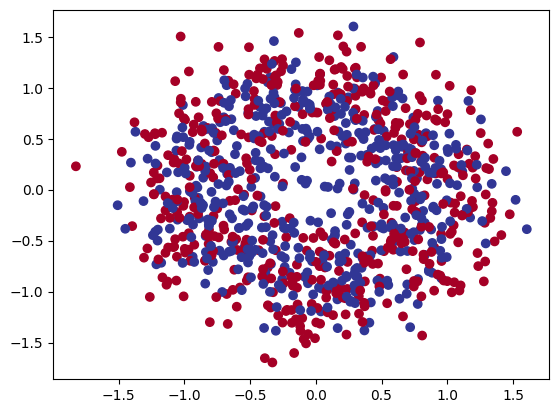

In [5]:
# Visualizing the data
import matplotlib.pyplot as plt
plt.scatter(x=x[:, 0],
            y=x[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu)

### checking inputs and outputs shapes

In [6]:
x.shape, y.shape

((1000, 2), (1000,))

In [7]:
x

array([[ 0.59171471,  0.43674853],
       [-0.45745002,  0.36160118],
       [-1.01069349,  0.83042101],
       ...,
       [-0.01985814, -1.02765007],
       [ 0.54269168, -1.11429774],
       [ 0.24539316,  1.01154823]], shape=(1000, 2))

In [8]:
x_sample = x[0]
y_sample = y[0]

print(f"values for one sample of x:{x_sample} and the same for y: {y_sample}")
print(f"shape for one sample of x:{x_sample.shape} and the ssame for y: {y_sample.shape}")


values for one sample of x:[0.59171471 0.43674853] and the same for y: 1
shape for one sample of x:(2,) and the ssame for y: ()


### Turning data into tensors

In [9]:
import torch

torch.__version__

'2.14.1+cpu'

In [10]:
x = torch.as_tensor(x, dtype=torch.float32)
y = torch.as_tensor(y, dtype=torch.float32)
x[:5], y[:5]

(tensor([[ 0.5917,  0.4367],
         [-0.4575,  0.3616],
         [-1.0107,  0.8304],
         [-0.8717,  0.4141],
         [ 0.4880, -0.8726]]),
 tensor([1., 1., 1., 1., 0.]))

In [11]:
type(x), x.dtype, y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [12]:
## Spliting the data into training and test sets

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size=0.2,# here we divided data into (80% training data and 20% testing data)
                                                    random_state=42)

In [13]:
len(x_train), len(x_test),len(y_train), len(y_test)

(800, 200, 800, 200)

In [14]:
n_samples

1000

### Building a model
to classify our red and blue dots

In [15]:
import torch
from torch import nn

#agnostic code
device = "GPU" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [16]:
x_train

tensor([[ 0.9182, -0.2022],
        [ 0.2415, -0.7090],
        [-1.1883,  0.1117],
        ...,
        [-0.1818, -1.3062],
        [ 1.2124,  0.3283],
        [ 0.5835, -0.5225]])

## Creating a model and to do that

1. subclasses `nn.module`
2. create 2 `nn.Linear()`
3. Define a `forward()`
Instatiate an instance of our model class and send it to the target `device`

In [17]:
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
#nn.linear is a capable of handling the shapes of our data
    self.layer_1 = nn.Linear(in_features=2, out_features=5)#takes in 2 feactures and upscales to 5 feactures
    self.layer_2 = nn.Linear(in_features=5, out_features=1)# takes in 5 feactures from previous layer and outputs a single feacture(same shape as y)
  def forward(self, x):
    return self.layer_2(self.layer_1(x))# x->layer_1 -> layer_2 -> output

model_0 = CircleModelV0()

model_0


CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [18]:
## Replicating above model (writes forward class itself)
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [19]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[ 0.1965,  0.3144],
                      [-0.4147, -0.5409],
                      [ 0.2719, -0.3260],
                      [ 0.1827, -0.3180],
                      [ 0.0231, -0.5465]])),
             ('0.bias', tensor([-0.3551,  0.3201, -0.0165,  0.1987, -0.3324])),
             ('1.weight',
              tensor([[-0.2408, -0.2264,  0.3817,  0.3031,  0.3189]])),
             ('1.bias', tensor([0.2401]))])

In [20]:
# Making predictions on untrained model
with torch.inference_mode():
  untrained_preds = model_0(x_test)
print(f"length of preds {len(untrained_preds)}, shape:{untrained_preds.shape}")
print(f"length of test samples: {len(x_test)}, shape: {x_test.shape}")
print(f"\nfirst 10 preds: \n {torch.round(untrained_preds[:10])}")
print(f"\nfirst 10 labels:\n {y_test[:10]}")


length of preds 200, shape:torch.Size([200, 1])
length of test samples: 200, shape: torch.Size([200, 2])

first 10 preds: 
 tensor([[-0.],
        [0.],
        [0.],
        [-0.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [-0.]])

first 10 labels:
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [21]:

## Setup loss function and optimizer
loss_fn = nn.BCEWithLogitsLoss() #build in sigmoid func and more stable then BCELoss

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)


In [22]:
##Calculate accuracy
def accuracy_fn(y_true, y_preds):
  correct = torch.eq(y_true, y_preds).sum().item()
  acc = (correct/len(y_preds)) * 100
  return acc
# print(acc)

### Training our model
* Forward pass
* Calculate loss
* Optimizer zero grad
* Loss backward(backpropagation)
*  step (Gradient desent)

### Going from raw logits -> Prediction Probabilities -> Prediction labels

**logits** : our model raw outputs are called logits
we can convert this into prediction probabilities by passing them to some kind of activation function (sigmoid, binary crossentropy and softmax for multiclassification)

In [23]:

model_0.eval()
with torch.inference_mode():
  y_logits = model_0(x_test)[:5]
y_logits

tensor([[-0.0380],
        [ 0.1171],
        [ 0.1569],
        [-0.1785],
        [ 0.7097]])

In [24]:
##Using sigmoid  activation fun on our logits to turn them into preds
## y_preds_probs >= 0.5 (y=1), (class 1)
## y_preds_probs <= 0.5 (y=0), (class 0)
y_preds_probs = torch.sigmoid(y_logits)
y_preds_probs.round()

tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.]])

In [25]:
## Find the predicts labels
y_preds = torch.round(y_preds_probs)
#In full (logits -> pred prob -> pred labels)
y_preds_labels = torch.round(torch.sigmoid(model_0(x_test)[:5]))
print(torch.eq(y_preds.squeeze(), y_preds_labels.squeeze()))

y_preds.squeeze()

tensor([True, True, True, True, True])


tensor([0., 1., 1., 0., 1.])

In [26]:
torch.manual_seed(42)
epoches = 1000
x_train, y_train = x_train, y_train
x_test, y_test = x_test, y_test
for epoch in range(epoches):
  #starting the training loop
  model_0.train()
  #forward pass
  y_logits = model_0(x_train).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))
  #Calculating loss
  loss = loss_fn(y_logits,
                 y_train)
  #Calculating accuracy
  acc = accuracy_fn(y_true=y_train,
                    y_preds=y_preds)
  #Setting grad zero
  optimizer.zero_grad
  #Backpropagatation
  loss.backward()
  #Gradient descent
  optimizer.step()

  model_0.eval()
  with torch.inference_mode():
    test_logits = model_0(x_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits,
                        y_test)
    test_acc = accuracy_fn(y_true = y_test,
                        y_preds = test_preds)

    if epoch % 10 ==0:
      print(f"Epoch: {epoch}|Loss: {loss:.5f}, Acc: {acc:.2f} % | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0|Loss: 0.71164, Acc: 53.00 % | Test loss: 0.69868, Test acc: 53.00%
Epoch: 10|Loss: 0.69780, Acc: 47.62 % | Test loss: 0.69911, Test acc: 49.00%
Epoch: 20|Loss: 0.69587, Acc: 49.00 % | Test loss: 0.70331, Test acc: 48.00%
Epoch: 30|Loss: 0.69996, Acc: 52.00 % | Test loss: 0.70509, Test acc: 50.00%
Epoch: 40|Loss: 0.69510, Acc: 48.88 % | Test loss: 0.69535, Test acc: 50.50%
Epoch: 50|Loss: 0.70365, Acc: 46.00 % | Test loss: 0.69601, Test acc: 50.00%
Epoch: 60|Loss: 0.69856, Acc: 50.38 % | Test loss: 0.69497, Test acc: 50.00%
Epoch: 70|Loss: 0.70432, Acc: 48.88 % | Test loss: 0.70982, Test acc: 48.50%
Epoch: 80|Loss: 0.69484, Acc: 52.00 % | Test loss: 0.70190, Test acc: 48.00%
Epoch: 90|Loss: 0.70389, Acc: 51.38 % | Test loss: 0.70354, Test acc: 47.50%
Epoch: 100|Loss: 0.70098, Acc: 49.25 % | Test loss: 0.70183, Test acc: 51.00%
Epoch: 110|Loss: 0.69833, Acc: 52.38 % | Test loss: 0.69965, Test acc: 50.00%
Epoch: 120|Loss: 0.69712, Acc: 50.00 % | Test loss: 0.69367, Test acc: 50.0

### Make predictions and evaluate the model - visulaize it



In [27]:
import requests
from pathlib import Path

# download helper function from learn pytorch repo

if Path("helper_function.py").is_file():
  print("helper_function.py already exist")
else:
  print("download helper_function")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/refs/heads/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)
from helper_functions import plot_predictions, plot_decision_boundary



download helper_function


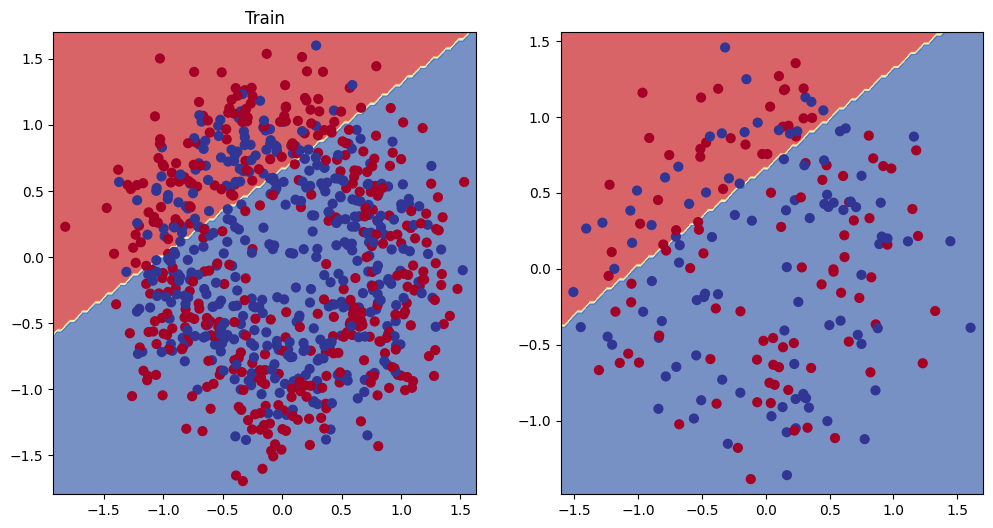

In [28]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_0, x_train, y_train)
plt.subplot(1,2,2)
plot_decision_boundary(model_0, x_test, y_test)

###Improving model

1. ADDS MORE LAYERS
2. ADD MORE HIDDEN LAYERS
3. FIT FOR LONGER
4. CHAGINIG THE ACTIVATION FUNCTION
5. CHANGE THE LEARNING RATE
6. CHANGE THE LOSS FUNCITON


In [29]:
class CircleModelV1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3 = nn.Linear(in_features=10, out_features=1)

  def forward(self, x):
    # z = self.layer_1(x)
    # z = self.layer_2(z)
    # z = self.layer_3(z)
    return self.layer_3(self.layer_2(self.layer_1(x))) # for speeding up
model_1 = CircleModelV1()
model_1



CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [30]:
## Setup loss function and optimizer
loss_fn = nn.BCEWithLogitsLoss() #build in sigmoid func and more stable then BCELoss

optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.1)

In [31]:
torch.manual_seed(42)
epoches = 1000
x_train, y_train = x_train, y_train
x_test, y_test = x_test, y_test
for epoch in range(epoches):
  #starting the training loop
  model_1.train()
  #forward pass
  y_logits = model_1(x_train).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))
  #Calculating loss
  loss = loss_fn(y_logits,
                 y_train)
  #Calculating accuracy
  acc = accuracy_fn(y_true=y_train,
                    y_preds=y_preds)
  #Setting grad zero
  optimizer.zero_grad
  #Backpropagation
  loss.backward()
  #Gradient descent
  optimizer.step()
#TESTING
  model_1.eval()
  with torch.inference_mode():
    test_logits = model_1(x_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits,
                        y_test)
    test_acc = accuracy_fn(y_true = y_test,
                        y_preds = test_preds)

    if epoch % 100 == 0:
      print(f"Epoch: {epoch}|Loss: {loss:.5f}, Acc: {acc:.2f} % | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0|Loss: 0.69370, Acc: 51.12 % | Test loss: 0.69300, Test acc: 48.50%
Epoch: 100|Loss: 0.69330, Acc: 52.38 % | Test loss: 0.69680, Test acc: 49.50%
Epoch: 200|Loss: 0.69303, Acc: 53.75 % | Test loss: 0.69439, Test acc: 49.00%
Epoch: 300|Loss: 0.69314, Acc: 51.88 % | Test loss: 0.69386, Test acc: 53.00%
Epoch: 400|Loss: 0.69324, Acc: 48.12 % | Test loss: 0.69598, Test acc: 50.50%
Epoch: 500|Loss: 0.69310, Acc: 45.75 % | Test loss: 0.69399, Test acc: 45.50%
Epoch: 600|Loss: 0.69327, Acc: 52.25 % | Test loss: 0.69399, Test acc: 51.00%
Epoch: 700|Loss: 0.69302, Acc: 53.12 % | Test loss: 0.69452, Test acc: 49.50%
Epoch: 800|Loss: 0.69315, Acc: 49.50 % | Test loss: 0.69350, Test acc: 48.50%
Epoch: 900|Loss: 0.69306, Acc: 53.50 % | Test loss: 0.69517, Test acc: 50.00%


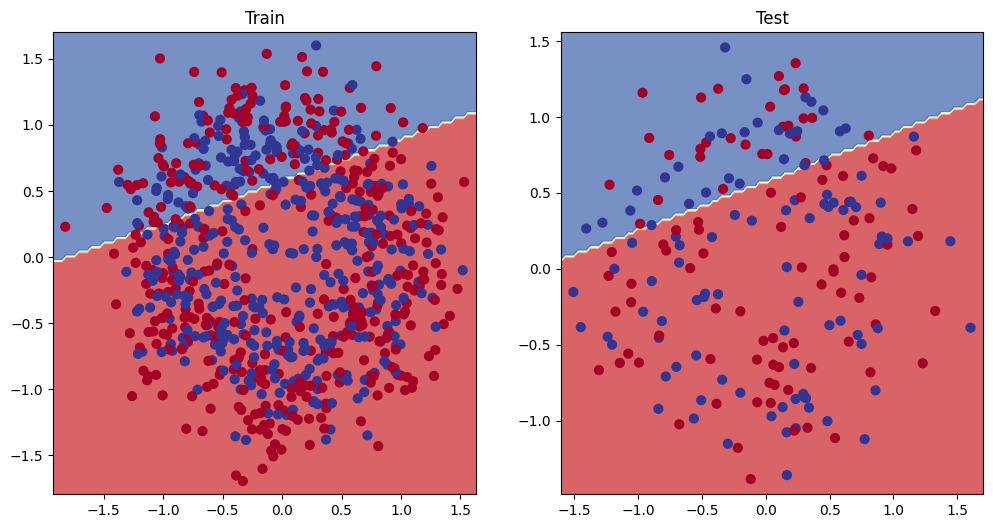

In [32]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_1, x_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1, x_test, y_test)

### Giving regression model data to check the model learns or not

In [33]:
weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.01

x_regression = torch.arange(start,end, step).unsqueeze(dim=1)
y_regression = weight * x_regression + bias

print(len(x_regression))
x_regression[:5], y_regression[:5]

100


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [34]:
train_split = int(0.8 * len(x_regression))
x_train_regression , y_train_regression = x_regression[:train_split], y_regression[:train_split]
x_test_regression, y_test_regression = x_regression[train_split:], y_regression[train_split:]

len(x_train_regression), len(y_train_regression), len(x_test_regression), len(y_test_regression)

(80, 80, 20, 20)

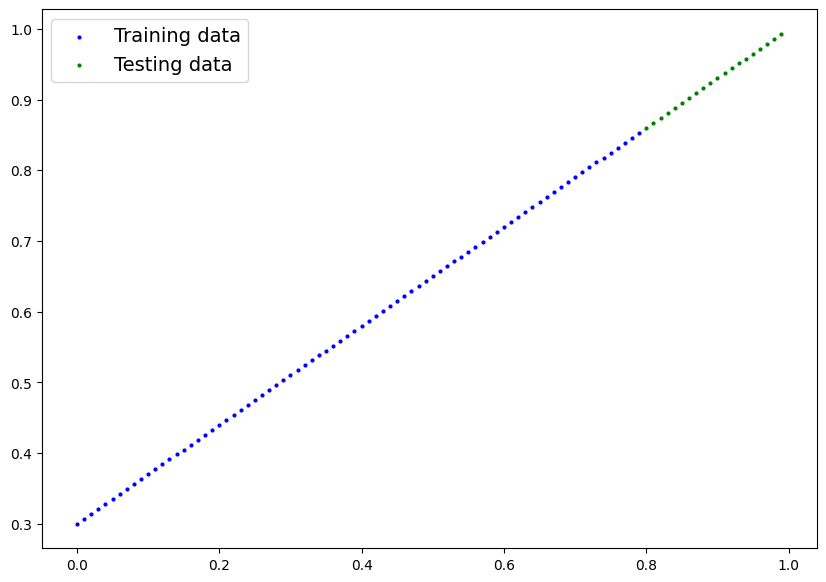

In [35]:
plot_predictions(train_data = x_train_regression,
                 train_labels = y_train_regression,
                 test_data = x_test_regression,
                 test_labels = y_test_regression)

In [36]:
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [37]:
model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
)
model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [38]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_2.parameters(),
                            lr=0.01)

In [39]:
torch.manual_seed(42)
epoches = 1000
x_train_regression, y_train_regression = x_train_regression, y_train_regression
x_test_regression, y_test_regression = x_test_regression, y_test_regression

for epoch in range(epoches):
  model_2.train()
  y_preds = model_2(x_train_regression)
  loss = loss_fn(y_preds, y_train_regression)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  model_2.eval()
  with torch.inference_mode():
    test_preds = model_2(x_test_regression)
    test_loss = loss_fn(test_preds, y_test_regression)
  if epoch % 100 == 0:
    print(f"Epoche: {epoch}|loss:{loss:.5f}| test loss: {test_loss:5f}")

Epoche: 0|loss:0.75986| test loss: 0.911029
Epoche: 100|loss:0.02858| test loss: 0.000813
Epoche: 200|loss:0.02533| test loss: 0.002092
Epoche: 300|loss:0.02137| test loss: 0.003051
Epoche: 400|loss:0.01964| test loss: 0.003408
Epoche: 500|loss:0.01940| test loss: 0.003873
Epoche: 600|loss:0.01903| test loss: 0.003789
Epoche: 700|loss:0.01878| test loss: 0.003813
Epoche: 800|loss:0.01840| test loss: 0.003287
Epoche: 900|loss:0.01798| test loss: 0.003604


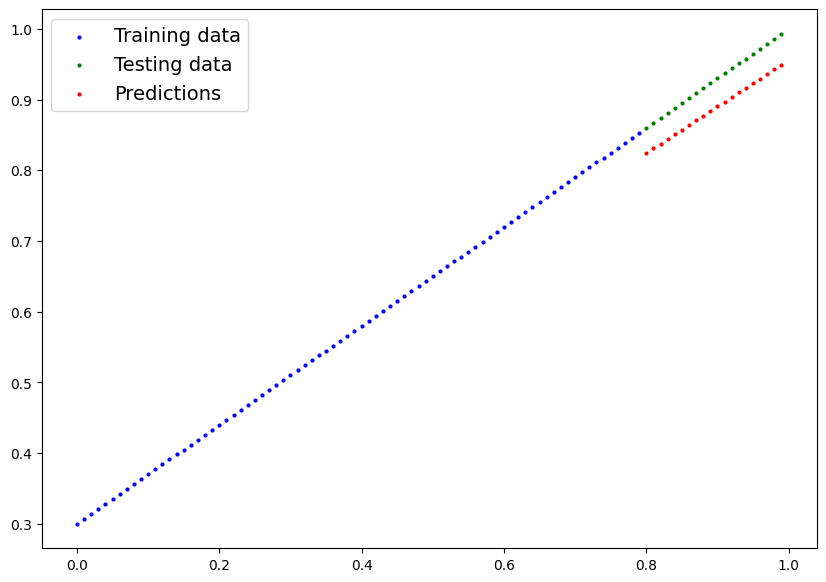

In [40]:
model_2.eval()

with torch.inference_mode():
  y_preds = model_2(x_test_regression)

plot_predictions(train_data = x_train_regression.cpu(),
                 train_labels = y_train_regression.cpu(),
                 test_data = x_test_regression.cpu(),
                 test_labels = y_test_regression.cpu(),
                 predictions=y_preds.cpu())

### The missing piece / non-linear
we are fitting non linear data to linear model that why's he model was not learning or improving

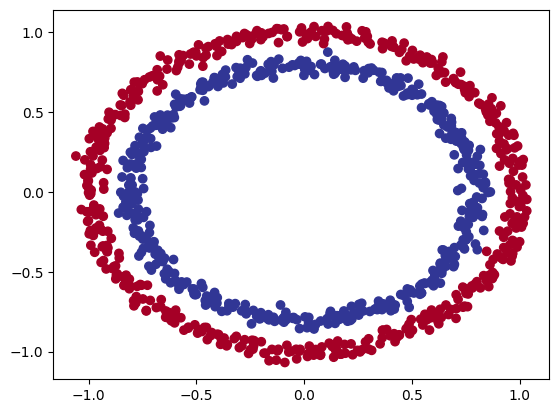

In [41]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000
X, y = make_circles(n_samples,
                    noise=0.03,
                    random_state=42)

plt.scatter(X[:, 0], X[:, 1],c=y, cmap=plt.cm.RdYlBu)

In [42]:
import torch
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
X_train[:5], y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

### Building a model with non-linearity

linear - stright line
non-linear - curve lines

In [51]:
from torch import nn
class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3 = nn.Linear(in_features=10, out_features=1)
    self.relu = nn.ReLU() #if it was (-) it makes 0 and (+) the positive ones
  def forward(self, x):
    return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))


model_3 = CircleModelV2()
model_3

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [52]:
## Setup loss function and optimizer
loss_fn = nn.BCEWithLogitsLoss() #build in sigmoid func and more stable then BCELoss

optimizer = torch.optim.SGD(params=model_3.parameters(),
                            lr=0.1)

In [58]:
torch.manual_seed(42)

X_train, y_train = X_train, y_train
X_test, y_test = X_test, y_test
epoches = 1000
for epoch in range(epoches):
  #starting the training loop
  model_3.train()
  #forward pass
  y_logits = model_3(X_train).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))
  #Calculating loss
  loss = loss_fn(y_logits,
                 y_train)
  #Calculating accuracy
  acc = accuracy_fn(y_true=y_train,
                    y_preds=y_preds)
  #Setting grad zero
  optimizer.zero_grad()
  #Backpropagation
  loss.backward()
  #Gradient descent
  optimizer.step()
#TESTING
  model_3.eval()
  with torch.inference_mode():
    test_logits = model_3(X_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits,
                        y_test)
    test_acc = accuracy_fn(y_true = y_test,
                        y_preds = test_preds)

    if epoch % 100 == 0:
      print(f"Epoch: {epoch}|Loss: {loss:.5f}, Acc: {acc:.2f} % | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0|Loss: 0.04176, Acc: 99.88 % | Test loss: 0.06583, Test acc: 100.00%
Epoch: 100|Loss: 0.03628, Acc: 99.88 % | Test loss: 0.05979, Test acc: 100.00%
Epoch: 200|Loss: 0.03205, Acc: 99.88 % | Test loss: 0.05460, Test acc: 100.00%
Epoch: 300|Loss: 0.02872, Acc: 99.88 % | Test loss: 0.05022, Test acc: 100.00%
Epoch: 400|Loss: 0.02604, Acc: 99.88 % | Test loss: 0.04662, Test acc: 100.00%
Epoch: 500|Loss: 0.02383, Acc: 99.88 % | Test loss: 0.04363, Test acc: 100.00%
Epoch: 600|Loss: 0.02196, Acc: 99.88 % | Test loss: 0.04091, Test acc: 100.00%
Epoch: 700|Loss: 0.02036, Acc: 99.88 % | Test loss: 0.03864, Test acc: 100.00%
Epoch: 800|Loss: 0.01898, Acc: 99.88 % | Test loss: 0.03680, Test acc: 100.00%
Epoch: 900|Loss: 0.01778, Acc: 99.88 % | Test loss: 0.03512, Test acc: 100.00%


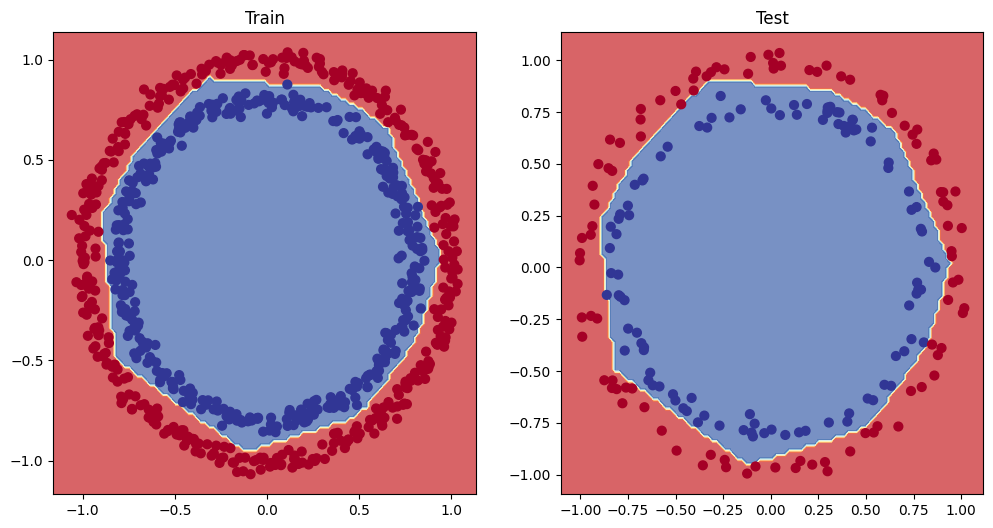

In [59]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)

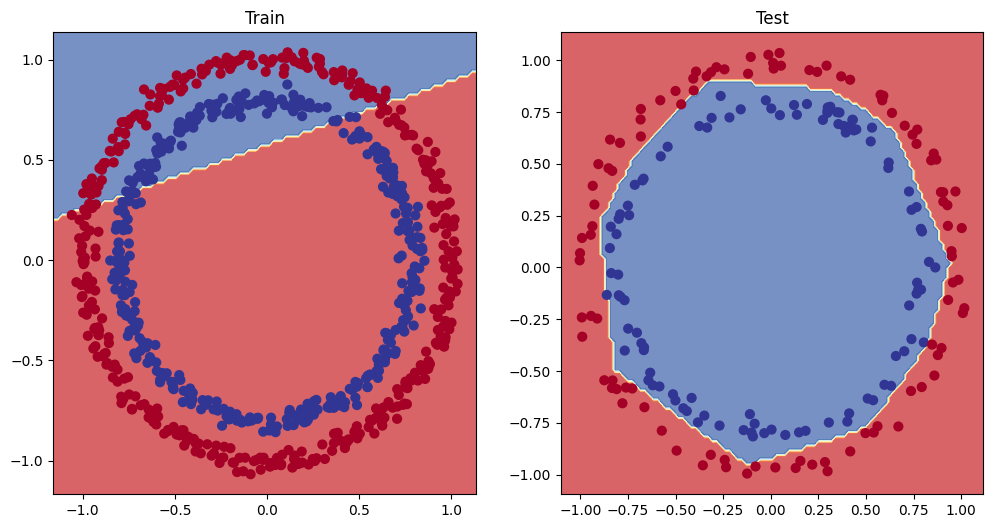

In [60]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_1, X_train, y_train) #Model 1 has no non-linearity
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test) #Model 3 has non-linearity

### EXPERMENTING WITH RELU ACTIVATION FUNCTION

In [65]:
# Replicating non linear function
import torch
A = torch.arange(-10, 10,1, dtype=torch.float32)
A.dtype

torch.float32

In [72]:
A


tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])

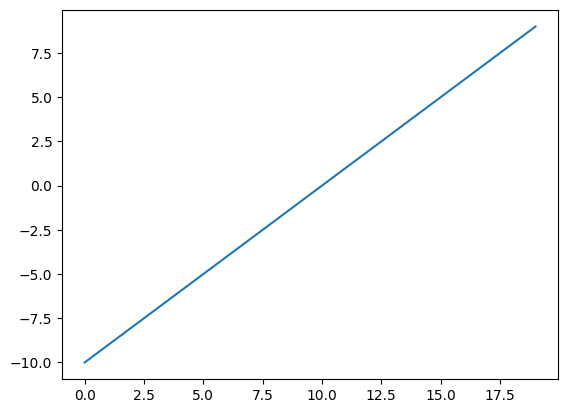

In [66]:
plt.plot(A)

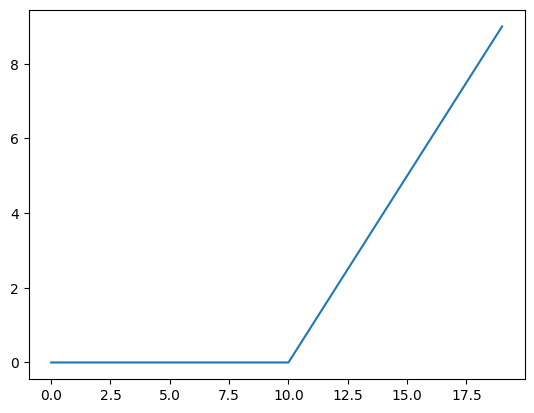

In [67]:
plt.plot(torch.relu(A))

In [69]:
def relu(x: torch.Tensor) -> torch.Tensor:
  return torch.maximum(torch.tensor(0), x)
relu(A)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 2., 3., 4., 5., 6., 7.,
        8., 9.])

### Experimenting with sigmoid activation function

In [73]:
##NOW LETS DO SAME FOR SIGMOID
def sigmoid():
  return 1/ (1 + torch.exp(-A))

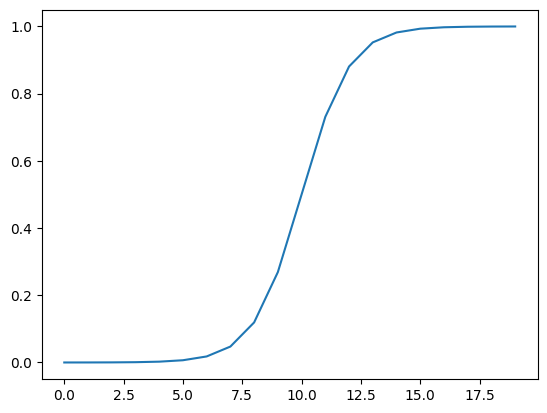

In [75]:
plt.plot(torch.sigmoid(A))

### EXPERMENTING WITH TANH ACTIVATION FUNCTION

In [77]:
from math import exp
def tanh():
  return torch.expo(x) - torch.exp(-x) / torch.exp(x) + torch.exp(-x)

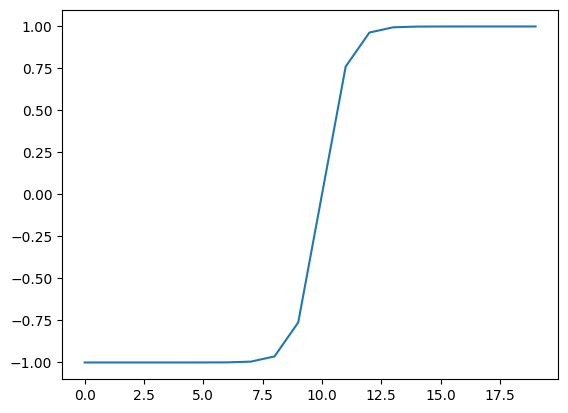

In [79]:
plt.plot(torch.tanh(A))

### Putting all together with a multi-class classification problem

1. Binary classification : One thing or another (spam/not-spam),(cat/dog)
2. Multi-class classification : More then one thing or another (cat/dog/hen)

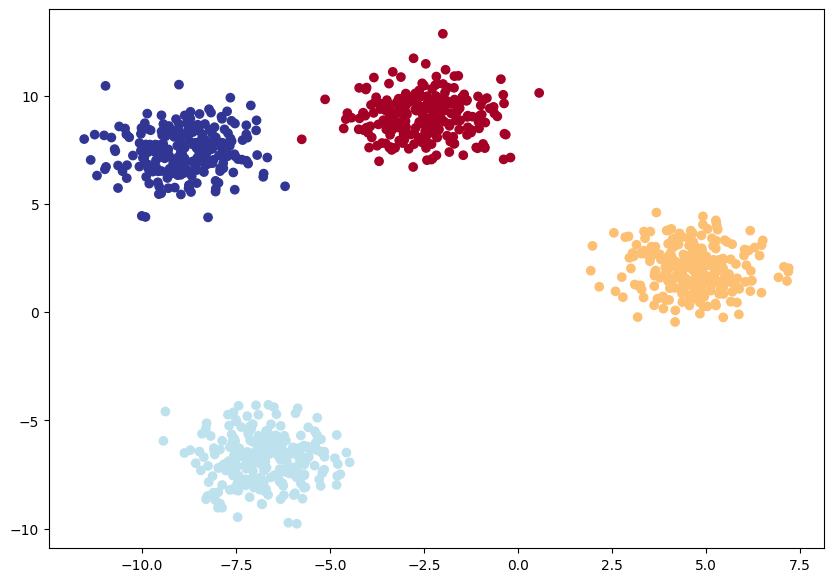

In [83]:
# Creating a toy multi class dataset
import torch
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters for data creation
NUM_CLASSES = 4
NUM_FEACTURES = 2
RANDOM_SEED = 42

# Create multi-class data
X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=NUM_FEACTURES,
                            centers=NUM_CLASSES,
                            cluster_std=1,
                            random_state=RANDOM_SEED)
# TURN DATA INTO TENSORS
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.float)

#Split into train and test

X_blob_train,X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob,
                                                                       y_blob,
                                                                       test_size=0.2,
                                                                       random_state=RANDOM_SEED)

 #Ploting the data visualize

plt.figure(figsize=(10,7))
plt.scatter(X_blob[:,0], X_blob[:,1], c=y_blob, cmap=plt.cm.RdYlBu)

In [86]:
X_blob.shape, y_blob.shape

(torch.Size([1000, 2]), torch.Size([1000]))